---
title: "Лабораторна робота 1. Формалізація складної системи та побудова її обчислювальної моделі"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

Лабораторна робота виконується після опрацювання Лекції 1 та є першим етапом *наскрізного модельно-обчислювального дослідження* курсу.

Її результат -- не просто працездатний код, а два пов'язані дослідницькі артефакти:

1. *специфікація моделі (model specification)*;
2. *виконувана обчислювальна модель (executable computational model)*.

У наступних лабораторних роботах ця модель або її дослідницький аналог послідовно доповнюватиметься аналізом динаміки, структури, калібруванням, V&V, аналізом чутливості, UQ та дизайном обчислювального експерименту.
:::

# Мета роботи

Набути практичної здатності переходити від дослідницького питання про складну систему до її концептуальної, математичної та обчислювальної моделі; обґрунтовувати межі системи, рівень опису, змінні, параметри, взаємодії та модельні припущення; реалізовувати мінімальну виконувану модель у Python і перевіряти її базову обчислювальну працездатність.

# Завдання роботи

1. Сформулювати дослідницьке питання (*research question, RQ*).
2. Визначити межі системи (*system boundary*) та її середовище.
3. Виділити компоненти, змінні стану, параметри, входи та виходи.
4. Зафіксувати рівень опису -- micro/meso/macro.
5. Сформулювати модельні припущення та обмеження.
6. Побудувати концептуальну схему системи.
7. Перейти до математичної формалізації.
8. Реалізувати мінімальну виконувану модель у Python.
9. Провести первинний обчислювальний експеримент.
10. Виконати критичний аудит моделі та перенести процедуру на власний дисертаційний об'єкт.

::: callout-important
## Методологічний принцип

У цій роботі **код не є початком моделювання**.

Послідовність має бути такою:

\[
\boxed{
\text{Research Question}
\rightarrow
\text{System Boundary}
\rightarrow
\text{Conceptual Model}
\rightarrow
\text{Mathematical Model}
\rightarrow
\text{Executable Model}
}
\]

Саме перехід між цими рівнями і його обґрунтування є предметом лабораторної роботи [@sayama2015; @oberkampfRoy2010].
:::

# Теоретичні відомості

Модель складної системи є цілеспрямованим спрощенням реального об'єкта, а не його копією. Тому її структура має визначатися не прагненням «включити все», а дослідницьким питанням, доступними даними та тим типом наукового висновку, який планується отримати [@mitchell2009; @sayama2015].

У цій лабораторній роботі використовуємо робочий опис системи

\[
S(t)=\bigl(V(t),E(t),X(t),\Theta,\mathcal{R},\mathcal{E}(t)\bigr),
\]

де:

- \(V(t)\) -- компоненти системи;
- \(E(t)\) -- структура взаємодій;
- \(X(t)\) -- стан системи;
- \(\Theta\) -- параметри;
- \(\mathcal{R}\) -- правила еволюції;
- \(\mathcal{E}(t)\) -- середовище.

Цей запис не нав'язує конкретний клас моделей. Він працює як *чекліст формалізації*.

## Логіка лабораторної роботи

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'tertiaryColor': '#E7F6EC',
  'lineColor': '#536878'
}}}%%
flowchart LR
    A("Дослідницьке<br/>питання") --> B("Межі<br/>системи")
    B --> C("Концептуальна<br/>модель")
    C --> D("Математична<br/>формалізація")
    D --> E("Обчислювальна<br/>модель")
    E --> F("Первинний<br/>експеримент")
    F --> G("Критичний<br/>аудит")
```

# Частина I. Навчальний кейс

Розглянемо умовну систему поширення інформації в онлайн-спільноті. Нас не цікавить відтворення конкретної соціальної платформи. Кейс потрібний для відпрацювання *процедури формалізації*.

Нехай у спільноті частина користувачів ще не поширює повідомлення, а частина -- активно його поширює. Активність може:

- зростати через взаємодію активних і неактивних користувачів;
- зменшуватися через втрату інтересу;
- підтримуватися слабким зовнішнім інформаційним впливом.

Такі моделі є лише одним із можливих рівнів абстракції інформаційного поширення. Мережні механізми ми свідомо поки не вводимо -- до них повернемося у темах про складні мережі [@newman2018; @barabasi2016].

# 1. Формулювання дослідницького питання

Для навчального кейсу зафіксуємо:

> *RQ:* як співвідношення між внутрішнім механізмом поширення, втратою активності та зовнішнім впливом визначає макроскопічну частку активних користувачів у часі?

Зверніть увагу: це питання вже обмежує майбутню модель.

Ми не запитуємо:

- хто саме поширить повідомлення;
- якою буде структура каскаду;
- які користувачі є центральними;
- який текст повідомлення;
- якою є реальна топологія соціальної мережі.

Отже, для цього RQ індивідуальний мережний опис поки не є обов'язковим.

# 2. Межі системи та середовище

Визначимо *систему* як фіксовану онлайн-спільноту з \(N\) користувачів.

Усередині меж системи моделюємо:

- поточну частку активних користувачів;
- внутрішнє поширення активності;
- втрату активності.

Зовнішнім середовищем вважаємо інформаційний вплив, що надходить поза межами спільноти.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'tertiaryColor': '#E7F6EC',
  'lineColor': '#536878'
}}}%%
flowchart LR
    ENV("Зовнішнє<br/>середовище") -->|"u"| S("Онлайн-спільнота")
    S --> A("Активні")
    S --> I("Неактивні")
    A -->|"внутрішній вплив"| I
    A -->|"втрата активності"| S
```

# 3. Рівень опису

Обираємо *макрорівень (macro level)*.

Нехай

\[
x(t)\in[0,1]
\]

-- частка активних користувачів у момент часу \(t\).

Тоді \(1-x(t)\) -- частка неактивних.

Ми свідомо агрегуємо індивідуальні стани користувачів у одну макрозмінну. Це означає втрату інформації про:

- гетерогенність користувачів;
- топологію взаємодій;
- локальні спільноти;
- індивідуальну історію;
- часову структуру контактів.

Таке спрощення допустиме лише відносно сформульованого RQ.

# 4. Паспорт моделі (model specification)

| Елемент | Формалізація для навчального кейсу |
|---|---|
| Дослідницьке питання | як механізми поширення, згасання та зовнішнього впливу визначають \(x(t)\) |
| Межа системи | одна фіксована онлайн-спільнота |
| Середовище | зовнішній інформаційний простір |
| Рівень опису | macro |
| Змінна стану | \(x(t)\) -- частка активних |
| Параметри | \(\beta,\gamma,u\) |
| Вхід | зовнішній вплив \(u\) |
| Вихід | траєкторія \(x(t)\) |
| Взаємодія | агрегований контакт активних і неактивних |
| Час | неперервний |
| Невизначеність | на цьому етапі не моделюється явно |
| Ціль | дослідити якісну макродинаміку |

# 5. Модельні припущення

Зафіксуємо припущення **до** написання коду.

1. Розмір спільноти в межах модельного часу не змінюється.
2. Усі користувачі агрегуються у дві групи -- активні та неактивні.
3. Внутрішній вплив пропорційний добутку \(x(1-x)\).
4. Втрата активності пропорційна \(x\).
5. Зовнішній вплив \(u\) є сталим.
6. Просторова та мережна структура не враховується.
7. Параметри не змінюються в часі.
8. Стохастичність поки не враховується.
9. Модель описує механізм на якісному рівні й не є відкаліброваною за реальними даними.

::: callout-warning
## Важливо

Припущення -- не «недоліки, які треба приховати». Це частина наукового визначення моделі. У подальшому саме вони задають область її застосовності та межі можливих висновків [@oberkampfRoy2010].
:::

# 6. Математична формалізація

Запишемо найпростішу нелінійну модель:

$$
\frac{dx}{dt} = \beta x(1-x) - \gamma x + u(1-x), 
$$

де:

- $\beta > 0$ -- інтенсивність внутрішнього поширення;
- $\gamma > 0$ -- інтенсивність втрати активності;
- $u\ge 0$ -- зовнішній інформаційний вплив.

Інтерпретуємо складові окремо:

$$ 
\underbrace{\beta x(1-x)}_{\text{внутрішнє поширення}} - \underbrace{\gamma x}_{\text{втрата активності}} + \underbrace{u(1-x)}_{\text{зовнішній вплив}}.
$$

Модель є нелінійною через множник $x(1-x)$. Навіть у такому агрегованому описі ми вже маємо конкуренцію механізмів, що формують динаміку системи.

# 7. Від математичної до обчислювальної моделі

Для чисельного інтегрування використаємо `solve_ivp` із бібліотеки [SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html).

На цьому етапі важливо розрізняти:

$$
\text{математична модель}
\neq
\text{програмна реалізація}.
$$

Програмний код є реалізацією математичної постановки. У подальшому курсі ми окремо перевірятимемо, чи правильно код реалізує рівняння -- це частина *верифікації (verification)* [@oberkampfRoy2010].

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

# 8. Реалізація правої частини моделі

In [2]:
def information_dynamics(t, y, beta, gamma, u):
    """
    Права частина математичної моделі.

    y[0]  -- частка активних користувачів x(t)
    beta  -- інтенсивність внутрішнього поширення
    gamma -- інтенсивність втрати активності
    u     -- зовнішній інформаційний вплив
    """
    x = y[0]

    internal_spread = beta * x * (1 - x)
    activity_loss = gamma * x
    external_influence = u * (1 - x)

    dxdt = internal_spread - activity_loss + external_influence
    return [dxdt]

# 9. Параметри базового сценарію

На першому етапі значення параметрів є *демонстраційними*, а не оціненими з даних.

Це принципово: число в коді не стає емпірично обґрунтованим параметром лише тому, що модель із ним працює.

In [3]:
params = {
    "beta": 0.8,
    "gamma": 0.35,
    "u": 0.03,
}

x0 = 0.05
t_start = 0
t_end = 40
t_eval = np.linspace(t_start, t_end, 401)

params

{'beta': 0.8, 'gamma': 0.35, 'u': 0.03}

# 10. Запуск обчислювальної моделі

In [4]:
solution = solve_ivp(
    fun=information_dynamics,
    t_span=(t_start, t_end),
    y0=[x0],
    t_eval=t_eval,
    args=(params["beta"], params["gamma"], params["u"]),
)

if not solution.success:
    raise RuntimeError(solution.message)

result = pd.DataFrame({
    "t": solution.t,
    "x": solution.y[0],
})

result.head()

,t,x
0,0.0,0.050000
1,0.1,0.054984
2,0.2,0.060135
3,0.3,0.065457
4,0.4,0.070948


# 11. Базові перевірки результату

Ще до наукової інтерпретації перевіримо елементарні властивості результату:

- інтегратор завершив роботу успішно;
- значення скінченні;
- частка активних не виходить за фізично інтерпретований інтервал \([0,1]\).

Це **не є повною V&V**. Це лише мінімальні sanity checks.

In [5]:
assert solution.success
assert np.isfinite(result["x"]).all()
assert ((result["x"] >= -1e-10) & (result["x"] <= 1 + 1e-10)).all()

print("Мінімальне x(t):", result["x"].min())
print("Максимальне x(t):", result["x"].max())
print("Кінцеве x(t):", result["x"].iloc[-1])

Мінімальне x(t): 0.05
Максимальне x(t): 0.5889742789249396
Кінцеве x(t): 0.5886173279245808


# 12. Візуалізація траєкторії

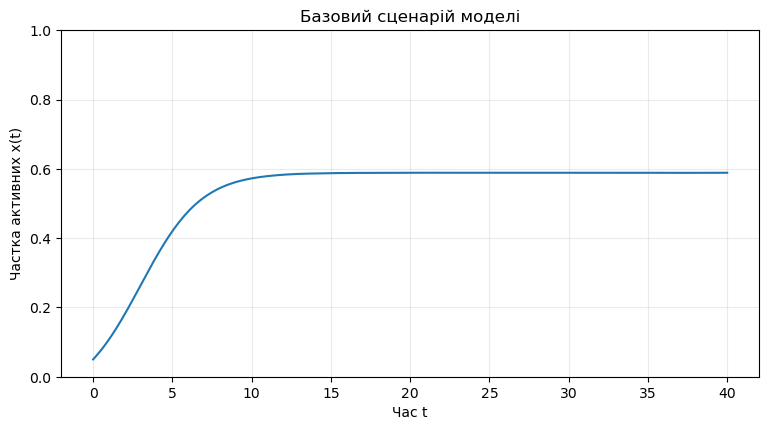

In [6]:
plt.figure(figsize=(9, 4.5))
plt.plot(result["t"], result["x"])
plt.xlabel("Час t")
plt.ylabel("Частка активних x(t)")
plt.title("Базовий сценарій моделі")
plt.grid(alpha=0.25)
plt.ylim(0, 1)
plt.show()

## Інтерпретація

Після виконання комірки не обмежуйтеся описом форми кривої.

Сформулюйте:

1. який режим поведінки спостерігається;
2. який механізм у рівнянні може його пояснювати;
3. що саме є *результатом моделі*;
4. що з цього вже можна вважати *науковим свідченням (scientific evidence)*;
5. чого **не можна** стверджувати без калібрування та валідації.

Останні два пункти особливо важливі: `model output` сам по собі ще не є доказом властивості реальної системи [@oberkampfRoy2010].

# 13. Первинний обчислювальний експеримент

Змінимо лише один параметр -- $\beta$ -- і порівняємо траєкторії.

Це ще не повний *аналіз чутливості (Sensitivity Analysis)*. Мета -- побачити, що параметр моделі кодує припущення про силу певного механізму, а зміна параметра є зміною модельного сценарію.

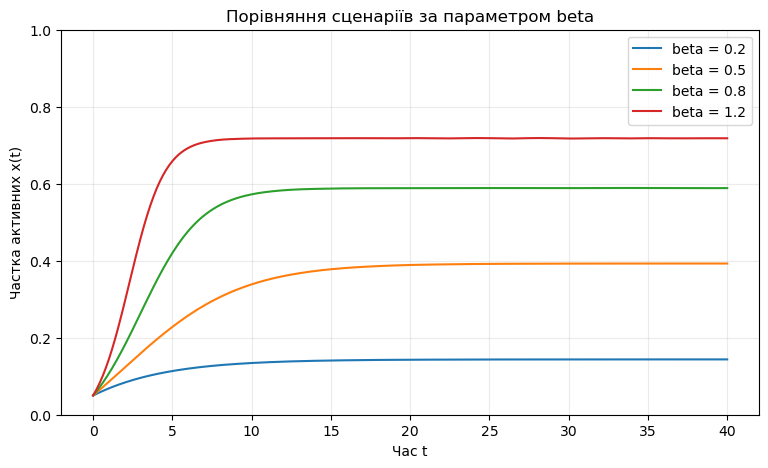

In [7]:
beta_values = [0.2, 0.5, 0.8, 1.2]

plt.figure(figsize=(9, 5))

for beta in beta_values:
    sol = solve_ivp(
        information_dynamics,
        (t_start, t_end),
        [x0],
        t_eval=t_eval,
        args=(beta, params["gamma"], params["u"]),
    )
    plt.plot(sol.t, sol.y[0], label=f"beta = {beta}")

plt.xlabel("Час t")
plt.ylabel("Частка активних x(t)")
plt.title("Порівняння сценаріїв за параметром beta")
plt.grid(alpha=0.25)
plt.ylim(0, 1)
plt.legend()
plt.show()

# 14. Критичний аудит навчальної моделі

Заповніть таблицю після виконання експерименту.

| Питання аудиту | Відповідь здобувача |
|---|---|
| Яке RQ підтримує ця модель? | |
| Які механізми представлені явно? | |
| Які механізми виключені? | |
| Яка інформація втрачена через macro-рівень? | |
| Які параметри потребують ідентифікації за даними? | |
| Які дані були б потрібні для валідації? | |
| Який результат є лише model output? | |
| Який висновок про реальну систему поки не обґрунтований? | |
| За яких умов модель слід відхилити або ускладнити? | |

::: callout-tip
## Критерій якості

Сильна відповідь не намагається довести, що модель «правильна». Вона чітко визначає, *для якого питання, за яких припущень і в яких межах* ця модель може бути корисною.
:::

# Частина II. Перенесення на дисертаційне дослідження

Тепер повторіть процедуру **для власного об'єкта дослідження**.

Не потрібно одразу будувати повну дисертаційну модель. Завдання ЛР1 -- створити її *мінімальну дослідницьку специфікацію*.

## 15. Дослідницьке питання

Сформулюйте одне питання у формі, яка допускає модельне дослідження.

> **RQ:** ...

Перевірте, чи містить воно:

- об'єкт або процес;
- властивість/механізм, що досліджується;
- змінні або ефекти, які потенційно можна спостерігати;
- можливість відповісти через математичну або обчислювальну модель.

# 16. Паспорт власної моделі

Заповніть таблицю.

| Елемент | Специфікація |
|---|---|
| Об'єкт дослідження | |
| Дослідницьке питання | |
| Межа системи | |
| Зовнішнє середовище | |
| Компоненти \(V\) | |
| Взаємодії \(E\) | |
| Змінні стану \(X\) | |
| Параметри \(\Theta\) | |
| Входи | |
| Виходи / observables | |
| Рівень опису | micro / meso / macro |
| Час | дискретний / неперервний |
| Основні правила \(\mathcal{R}\) | |
| Джерела невизначеності | |
| Ключові припущення | |
| Що модель свідомо не описує | |

# 17. Концептуальна схема власної системи

Побудуйте Mermaid-схему, яка відображає **не програмні модулі**, а модельну структуру: компоненти, середовище, основні взаємодії, входи та виходи.

Замініть приклад нижче власною схемою.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'tertiaryColor': '#E7F6EC',
  'lineColor': '#536878'
}}}%%
flowchart LR
    ENV("Середовище") --> S("Досліджувана система")
    A("Компонент A") --> S
    B("Компонент B") --> S
    S --> Y("Спостережуваний<br/>результат")
```

# 18. Математична формалізація власної моделі

Запишіть мінімальну математичну постановку.

Залежно від задачі це може бути:

$$
X_{t+1}=F(X_t,U_t,\Theta),
$$

або

$$
\dot X(t)=F(X(t),U(t),\Theta),
$$

або мережна, стохастична, агентна чи інша форма.

Поясніть **кожний символ** і покажіть відповідність між концептуальною схемою та математичними об'єктами.

Якщо повна математична модель ще не визначена, сформулюйте її структурний каркас і чітко позначте невизначені компоненти. Це краще, ніж приховувати концептуальну невизначеність за кодом.

# 19. Мінімальна виконувана модель

Реалізуйте *мінімальну* версію власної моделі в Python.

Вимоги:

- параметри не мають бути «зашиті» всередині функції без пояснення;
- кожна змінна повинна мати модельний зміст;
- код має відповідати математичній постановці;
- випадкові процедури повинні мати фіксований `random_state` / seed;
- результат має бути представлений у формі, придатній для подальшого аналізу;
- необхідно виконати хоча б одну базову перевірку коректності результату.

```python
# Розмістіть тут реалізацію власної моделі.
```

# 20. Мінімальний обчислювальний експеримент

Проведіть один контрольований експеримент:

$$
\text{одна зміна в постановці}
\rightarrow
\text{спостережувана зміна результату}.
$$

Наприклад:

- змініть один параметр;
- змініть початковий стан;
- порівняйте два структурні припущення;
- увімкніть/вимкніть один механізм.

Не робіть багато сценаріїв. Тут важливіше показати причинну логіку експерименту:

> *Що саме я змінив у моделі, чому саме це змінив і яку зміну результату очікую побачити?*

# 21. Підсумковий модельний артефакт ЛР1

Після виконання роботи у вас має бути:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'tertiaryColor': '#E7F6EC',
  'lineColor': '#536878'
}}}%%
flowchart LR
    RQ("Research<br/>Question") --> MS("Model<br/>Specification")
    MS --> MM("Mathematical<br/>Model")
    MM --> CM("Executable<br/>Model")
    CM --> CE("Minimal Computational<br/>Experiment")
    CE --> CA("Critical<br/>Audit")
```

Це -- *версія 0.1* вашого наскрізного дослідницького артефакту. Не намагайтеся зробити її остаточною: наступні лабораторні роботи мають давати підстави змінювати й уточнювати модель.

# Контрольні питання

1. Чому модель складної системи не можна розглядати як копію реального об'єкта?
2. Як дослідницьке питання впливає на межі системи?
3. У чому різниця між змінною стану, параметром, входом і спостережуваною величиною?
4. Чому вибір micro/meso/macro-рівня є науковим, а не лише технічним рішенням?
5. Яку інформацію може втратити агрегована модель?
6. Чому модельні припущення потрібно фіксувати до інтерпретації результатів?
7. Чим математична модель відрізняється від її програмної реалізації?
8. Що означає «мінімальна виконувана модель»?
9. Чому працездатний код ще не підтверджує адекватність моделі реальній системі?
10. Чим `model output` відрізняється від `scientific evidence`?
11. Які результати ЛР1 у подальшому потребуватимуть ідентифікації та калібрування?
12. Які елементи моделі мають бути перевірені під час V&V?

# Вимоги до звіту

Звіт виконується безпосередньо в `.ipynb`-зошиті на основі цього шаблону.

У звіті мають бути:

1. тема та мета роботи;
2. дослідницьке питання;
3. визначення меж системи та середовища;
4. заповнений паспорт моделі;
5. концептуальна Mermaid-схема;
6. математична формалізація;
7. виконувана реалізація в Python;
8. результати мінімального обчислювального експерименту;
9. базові перевірки обчислювального результату;
10. критичний аудит моделі;
11. висновки щодо того, *що саме вже дозволяє стверджувати модель, а що ще потребує доказової перевірки*.

::: callout-important
## Оцінюється

Не складність програмного коду, а узгодженість ланцюга

$$
RQ
\rightarrow
\text{formalization}
\rightarrow
\text{model}
\rightarrow
\text{experiment}
\rightarrow
\text{interpretation}.
$$
:::

# Висновки

У висновках дайте стислу відповідь на чотири питання:

1. *Яку складну систему та яке дослідницьке питання було формалізовано?*
2. *Які припущення визначають побудовану модель?*
3. *Яку поведінку продемонструвала виконувана модель у мінімальному експерименті?*
4. *Яких перевірок бракує, перш ніж використовувати її результати як підставу для наукового висновку про реальну систему?*

# Джерела та корисні ресурси

У роботі використовується спільна накопичувальна бібліографічна база курсу `mmss-references.bib`.

Корисні ресурси:

- [SciPy -- `solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [Matplotlib documentation](https://matplotlib.org/stable/)
- [Project Jupyter](https://jupyter.org/)
- [Introduction to the Modeling and Analysis of Complex Systems -- Hiroki Sayama](https://milneopentextbooks.org/introduction-to-the-modeling-and-analysis-of-complex-systems/)
- [Network Science -- Albert-László Barabási](https://networksciencebook.com/)

# References